# Generalized Eigenvalue Problem Solver
## Solving det(A - λB) = 0

**Problem:** Find all eigenvalues λ such that det(A - λB) = 0

This is a **generalized eigenvalue problem** of the form: **Aw = λBw**

## Step 1: Set Xs, Xt and Build K, L, H, A, B

We will:
- define source samples `Xs` and target samples `Xt`
- stack them as `X = vstack([Xs, Xt])`
- compute a linear kernel matrix `K = X X^T`
- build MMD matrix `L` using your piecewise formula
- build centering matrix `H = I_n - (1/n)11^T`
- construct:
  - `A = K L K + I_n`
  - `B = K H K`

In [ ]:
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt

# -----------------------------
# User-defined source/target data
# -----------------------------
# Rows are samples, columns are features.
Xs = np.array([
    [2.0, 3.0, 1.0],
    [4.0, 1.0, 2.0]
], dtype=float)

Xt = np.array([
    [5.0, 6.0, 2.0],
    [1.0, 2.0, 0.5]
], dtype=float)

# Stack source and target
X = np.vstack([Xs, Xt])
ns = Xs.shape[0]
nt = Xt.shape[0]
n = ns + nt

# Linear kernel matrix K (n x n)
# In TCA-style sample space, K should be sample-by-sample, so K = X X^T.
K = X @ X.T

# Build L using the provided piecewise rule
L = np.full((n, n), -1.0 / (ns * nt), dtype=float)
L[:ns, :ns] = 1.0 / (ns * ns)
L[ns:, ns:] = 1.0 / (nt * nt)

# Centering matrix H = I_n - (1/n)11^T
H = np.eye(n) - np.ones((n, n)) / n

# Construct A and B
A = K @ L @ K + np.eye(n)
B = K @ H @ K

print('Xs shape:', Xs.shape)
print('Xt shape:', Xt.shape)
print('X shape :', X.shape)
print('\nK = X X^T:\n', K)
print('\nL (MMD matrix):\n', L)
print('\nH (centering matrix):\n', H)
print('\nA = K L K + I:\n', A)
print('\nB = K H K:\n', B)
print(f'\nrank(B) = {np.linalg.matrix_rank(B)} out of {n}')

Xs shape: (2, 3)
Xt shape: (2, 3)
X shape : (4, 3)

K = X X^T:
 [[14.   13.   30.    8.5 ]
 [13.   21.   30.    7.  ]
 [30.   30.   65.   18.  ]
 [ 8.5   7.   18.    5.25]]

L (MMD matrix):
 [[ 0.25  0.25 -0.25 -0.25]
 [ 0.25  0.25 -0.25 -0.25]
 [-0.25 -0.25  0.25  0.25]
 [-0.25 -0.25  0.25  0.25]]

H (centering matrix):
 [[ 0.75 -0.25 -0.25 -0.25]
 [-0.25  0.75 -0.25 -0.25]
 [-0.25 -0.25  0.75 -0.25]
 [-0.25 -0.25 -0.25  0.75]]

A = K L K + I:
 [[ 34.0625     8.625     66.125     22.28125 ]
 [  8.625      3.25      17.25       5.8125  ]
 [ 66.125     17.25     133.25      44.5625  ]
 [ 22.28125    5.8125    44.5625    16.015625]]

B = K H K:
 [[ 264.6875    251.875     571.375     160.09375 ]
 [ 251.875     298.75      557.75      146.4375  ]
 [ 571.375     557.75     1236.75      344.1875  ]
 [ 160.09375   146.4375    344.1875     97.421875]]

rank(B) = 3 out of 4


## Step 2: Solve the Generalized Eigenvalue Problem

For the generalized eigenvalue problem **Aw = λBw**, we use `scipy.linalg.eig(A, B)` which solves:
- Returns eigenvalues λ and eigenvectors w
- These are the values of λ where det(A - λB) = 0

In [12]:
# Solve generalized eigenproblem in homogeneous form:
# alpha[i] * v = beta[i] * (lambda-form denominator)
# finite lambda_i = alpha_i / beta_i, infinite when beta_i = 0.
ab, eigenvectors = linalg.eig(A, B, homogeneous_eigvals=True)
alpha = ab[0]
beta = ab[1]

tol = 1e-12
is_infinite = np.abs(beta) < tol
finite_lambda = alpha[~is_infinite] / beta[~is_infinite]
finite_vecs = eigenvectors[:, ~is_infinite]

# Sort finite eigenvalues by real part (descending)
idx = np.argsort(-finite_lambda.real)
finite_lambda = finite_lambda[idx]
finite_vecs = finite_vecs[:, idx]

print('\n' + '=' * 68)
print('GENERALIZED EIGENVALUES FOR det(A - λB) = 0')
print('=' * 68)

for i, lam in enumerate(finite_lambda, start=1):
    if np.isreal(lam):
        print(f'Finite λ_{i} = {lam.real:.10f}')
    else:
        print(f'Finite λ_{i} = {lam.real:.10f} + {lam.imag:.10f}i')

num_inf = int(np.sum(is_infinite))
print(f'\nInfinite eigenvalues count = {num_inf}')
if num_inf > 0:
    print('Reason: beta = 0 for those generalized modes (typically due to singular B).')

print('=' * 68)


GENERALIZED EIGENVALUES FOR det(A - λB) = 0
Finite λ_1 = 2260.5816868864
Finite λ_2 = 0.4105383763
Finite λ_3 = 0.0052749178

Infinite eigenvalues count = 1
Reason: beta = 0 for those generalized modes (typically due to singular B).


## Step 3: Verify Solutions

In [13]:
# Verify only finite eigenvalues: det(A - λB) ≈ 0
print('\nVerification for finite eigenvalues (det(A - λB) ≈ 0):\n')

for i, lam in enumerate(finite_lambda, start=1):
    R = A - lam * B
    det_R = np.linalg.det(R)

    print(f'λ_{i} = {lam.real:.10f}' if np.isreal(lam) else f'λ_{i} = {lam}')
    print(f'   det(A - λB) = {det_R:.3e}')

    w = finite_vecs[:, i - 1]
    denom = np.linalg.norm(B @ w)
    residual = np.linalg.norm(A @ w - lam * (B @ w)) / (denom + 1e-15)
    print(f'   residual ||Aw - λBw|| / ||Bw|| = {residual:.3e}\n')


Verification for finite eigenvalues (det(A - λB) ≈ 0):

λ_1 = 2260.5816868864
   det(A - λB) = -8.110e+00+0.000e+00j
   residual ||Aw - λBw|| / ||Bw|| = 1.245e-06

λ_2 = 0.4105383763
   det(A - λB) = 8.985e-12+0.000e+00j
   residual ||Aw - λBw|| / ||Bw|| = 2.402e-16

λ_3 = 0.0052749178
   det(A - λB) = -3.496e-13+0.000e+00j
   residual ||Aw - λBw|| / ||Bw|| = 3.987e-17



## Step 4: Display Matrix (A - λB) for Each Eigenvalue

In [14]:
print('\n' + '=' * 70)
print('Matrix R = A - λB for each finite eigenvalue')
print('=' * 70)

for i, lam in enumerate(finite_lambda, start=1):
    R = A - lam * B
    print(f'\nFor finite λ_{i} = {lam.real:.10f}:' if np.isreal(lam) else f'\nFor finite λ_{i} = {lam}:')
    for row in R:
        print('  [' + '  '.join(f'{val:12.6f}' for val in row) + ']')
    print(f'det(R) = {np.linalg.det(R):.3e}')

if np.sum(is_infinite) > 0:
    print(f'\nSkipped {int(np.sum(is_infinite))} infinite eigenvalue(s) for R = A - λB display.')


Matrix R = A - λB for each finite eigenvalue

For finite λ_1 = 2260.5816868864:
  [-598313.652748+0.000000j  -569375.387385+0.000000j  -1291573.736345+0.000000j  -361882.718185+0.000000j]
  [-569375.387385+0.000000j  -675345.528957+0.000000j  -1260822.185861+0.000000j  -331028.118273+0.000000j]
  [-1291573.736345+0.000000j  -1260822.185861+0.000000j  -2795641.151257+0.000000j  -778019.396855+0.000000j]
  [-361882.718185+0.000000j  -331028.118273+0.000000j  -778019.396855+0.000000j  -220214.090902+0.000000j]
det(R) = -8.110e+00+0.000e+00j

For finite λ_2 = 0.4105383763:
  [-74.601876+0.000000j  -94.779354+0.000000j  -168.446365+0.000000j  -43.443378+0.000000j]
  [-94.779354+0.000000j  -119.398340+0.000000j  -211.727779+0.000000j  -54.305713+0.000000j]
  [-168.446365+0.000000j  -211.727779+0.000000j  -374.483337+0.000000j  -96.739677+0.000000j]
  [-43.443378+0.000000j  -54.305713+0.000000j  -96.739677+0.000000j  -23.979793+0.000000j]
det(R) = 8.985e-12+0.000e+00j

For finite λ_3 = 0.005

## Step 5: Eigenvectors

In [15]:
print('\n' + '=' * 70)
print('EIGENVECTORS (for finite eigenvalues):')
print('=' * 70)

for i, lam in enumerate(finite_lambda, start=1):
    w = finite_vecs[:, i - 1]
    print(f'\nEigenvector for finite λ_{i} = {lam.real:.10f}:' if np.isreal(lam) else f'\nEigenvector for finite λ_{i} = {lam}:')
    for j, val in enumerate(w):
        if np.isreal(val):
            print(f'  w[{j}] = {val.real:12.8f}')
        else:
            print(f'  w[{j}] = {val}')

if np.sum(is_infinite) > 0:
    print(f'\nThere are also {int(np.sum(is_infinite))} infinite generalized eigenvalue mode(s).')


EIGENVECTORS (for finite eigenvalues):

Eigenvector for finite λ_1 = 2260.5816868864:
  w[0] =   0.69036113
  w[1] =   0.17158135
  w[2] =  -0.52603910
  w[3] =   0.46609465

Eigenvector for finite λ_2 = 0.4105383763:
  w[0] =   0.31770861
  w[1] =  -0.85749797
  w[2] =   0.26230634
  w[3] =   0.30814583

Eigenvector for finite λ_3 = 0.0052749178:
  w[0] =   0.11382446
  w[1] =  -0.97750969
  w[2] =  -0.00617049
  w[3] =   0.17742809

There are also 1 infinite generalized eigenvalue mode(s).


## Step 6: Visualization - Eigenvalue Distribution

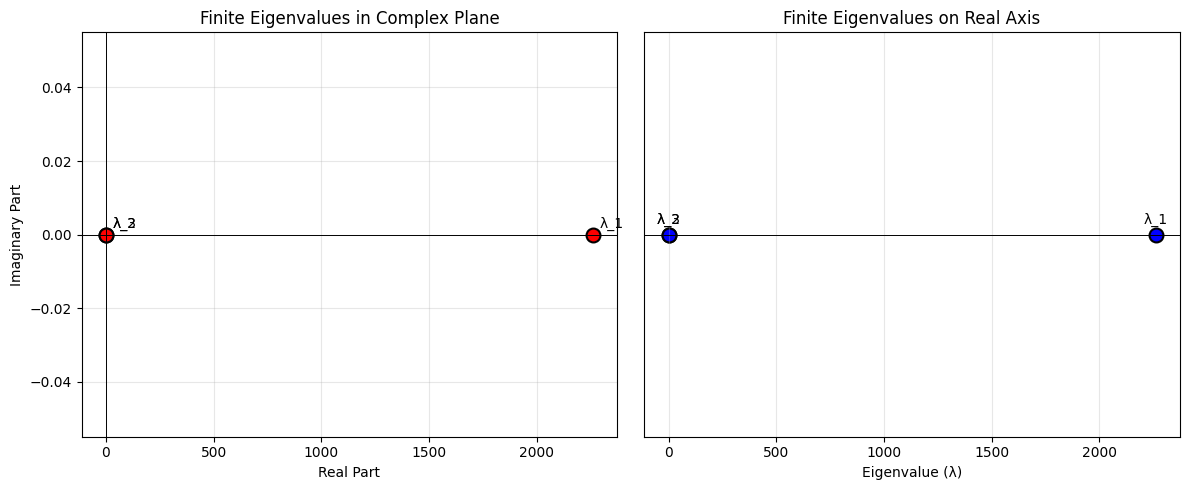


Finite eigenvalues plotted: 3
Infinite eigenvalues (not plotted): 1


In [16]:
if len(finite_lambda) == 0:
    print('No finite eigenvalues to plot.')
else:
    plt.figure(figsize=(12, 5))

    lam_real = finite_lambda.real
    lam_imag = finite_lambda.imag

    # Plot 1: finite eigenvalues in complex plane
    plt.subplot(1, 2, 1)
    plt.scatter(lam_real, lam_imag, s=100, color='red', edgecolors='black', linewidth=1.5)
    for i, (x, y) in enumerate(zip(lam_real, lam_imag), start=1):
        plt.annotate(f'λ_{i}', (x, y), xytext=(5, 5), textcoords='offset points')
    plt.axhline(0, color='k', linewidth=0.7)
    plt.axvline(0, color='k', linewidth=0.7)
    plt.xlabel('Real Part')
    plt.ylabel('Imaginary Part')
    plt.title('Finite Eigenvalues in Complex Plane')
    plt.grid(True, alpha=0.3)

    # Plot 2: finite eigenvalues on real axis
    plt.subplot(1, 2, 2)
    plt.scatter(lam_real, np.zeros_like(lam_real), s=100, color='blue', edgecolors='black', linewidth=1.5)
    for i, x in enumerate(lam_real, start=1):
        plt.annotate(f'λ_{i}', (x, 0), xytext=(0, 8), textcoords='offset points', ha='center')
    plt.axhline(0, color='k', linewidth=0.7)
    plt.xlabel('Eigenvalue (λ)')
    plt.title('Finite Eigenvalues on Real Axis')
    plt.yticks([])
    plt.grid(True, alpha=0.3, axis='x')

    plt.tight_layout()
    plt.show()

print(f'\nFinite eigenvalues plotted: {len(finite_lambda)}')
print(f'Infinite eigenvalues (not plotted): {int(np.sum(is_infinite))}')

## Step 7: Summary

In [17]:
print('\n' + '=' * 72)
print('SUMMARY - det(A - λB) = 0 (from Xs, Xt, K, L, H)')
print('=' * 72)

print(f'Xs shape: {Xs.shape}, Xt shape: {Xt.shape}, X shape: {X.shape}')
print(f'K shape : {K.shape}, rank(B): {np.linalg.matrix_rank(B)} / {B.shape[0]}\n')

print('Finite eigenvalues:')
if len(finite_lambda) == 0:
    print('  None')
else:
    for i, lam in enumerate(finite_lambda, start=1):
        if np.isreal(lam):
            print(f'  λ_{i} = {lam.real:.10f}')
        else:
            print(f'  λ_{i} = {lam.real:.10f} + {lam.imag:.10f}i')

print(f'\nInfinite eigenvalue count: {int(np.sum(is_infinite))}')
print('Note: Infinite modes occur when beta = 0 in the generalized problem (A, B).')
print('=' * 72)


SUMMARY - det(A - λB) = 0 (from Xs, Xt, K, L, H)
Xs shape: (2, 3), Xt shape: (2, 3), X shape: (4, 3)
K shape : (4, 4), rank(B): 3 / 4

Finite eigenvalues:
  λ_1 = 2260.5816868864
  λ_2 = 0.4105383763
  λ_3 = 0.0052749178

Infinite eigenvalue count: 1
Note: Infinite modes occur when beta = 0 in the generalized problem (A, B).
